## FNO-only Model

The FNO-only model processes the normalized input series through Fourier layers, followed by patch segmentation and mean pooling. The resulting representation is passed to a multi-label classification head.

The architecture is based on the Fourier Neural Operator proposed by Li et al. (2021).

Li, Z., Kovachki, N.B., Azizzadenesheli, K., Liu, B., Bhattacharya, K., Stuart, A.M., Anandkumar, A., 2021. Fourier neural operator for parametric partial differential equations, in: International Conference on Learning Representations (ICLR 2021). https://openreview.net/forum?id=c8P9NQVtmnO.

**Reference:**
Li, Z., Kovachki, N.B., Azizzadenesheli, K., Liu, B., Bhattacharya, K., Stuart, A.M., Anandkumar, A., 2021. Fourier neural operator for parametric partial differential equations, in: International Conference on Learning Representations (ICLR 2021). https://openreview.net/forum?id=c8P9NQVtmnO.

## 1. Libraries and Dependencies

In [1]:
import json
import math
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, Subset, DataLoader
from sklearn.metrics import (f1_score, accuracy_score, hamming_loss,
                             label_ranking_loss, roc_auc_score)
import matplotlib.pyplot as plt

## 2. Model and Training Configuration

In [ ]:
# Dataset path
DATA_DIR = Path("synthetic_dataset")

# Random seeds
SEEDS = [0, 1, 2, 3, 4]

# Data loading
BATCH_SIZE = 32

# Fourier Neural Operator
FNO_MODES = 384
FNO_WIDTH = 32
FNO_LAYERS = 2

# Patch segmentation
PATCH_SIZE = 8
D_MODEL = 128

# Classification head
DROPOUT = 0.1
N_LABELS = 4

# Optimization
LEARNING_RATE = 3e-4        
WEIGHT_DECAY = 1e-4
N_EPOCHS = 30

# Experiment identity and output paths
ARCH_NAME = "fno_only"
PRED_DIR = DATA_DIR / "predictions"
PRED_DIR.mkdir(exist_ok=True)

def checkpoint_path(seed):
    return DATA_DIR / f"best_{ARCH_NAME}_seed{seed}.pt"


# Computing device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


## 3. Dataset Loading

In [3]:

class CyclesDataset(Dataset):
    """Load synthetic sedimentary series and multi-label targets from NPZ
    and JSON files, with metadata aligned by sample index.
    """

    def __init__(self, npz_path, json_path):
        npz_path = Path(npz_path)
        json_path = Path(json_path)

        if not npz_path.exists():
            raise FileNotFoundError(f".npz file not found: {npz_path}")
        if not json_path.exists():
            raise FileNotFoundError(f".json file not found: {json_path}")

        npz_data = np.load(npz_path, allow_pickle=True)

        self.signals = npz_data["signals"]
        self.depths = npz_data["depths"]
        self.labels = npz_data["labels"]
        self.label_names = list(npz_data["label_names"])

        with open(json_path, "r", encoding="utf-8") as f:
            self.metadata = json.load(f)

        n_signals = self.signals.shape[0]
        n_meta = len(self.metadata)
        assert n_signals == n_meta, (
            f"Mismatch between .npz ({n_signals} series) and .json ({n_meta} entries). "
        )

    def __len__(self):
        return self.signals.shape[0]

    def __getitem__(self, idx: int):
        signal = torch.from_numpy(self.signals[idx]).float()
        depth = torch.from_numpy(self.depths[idx]).float()
        label = torch.from_numpy(self.labels[idx]).float()
        meta = self.metadata[idx]

        return {
            "signal": signal,
            "depth": depth,
            "label": label,
            "metadata": meta,
        }

## 4. Dataset Initialization

In [4]:
# Load the synthetic dataset and verify its size and label order.
ds = CyclesDataset(
    npz_path=DATA_DIR / "synthetic_cyclostratigraphy_dataset.npz",
    json_path=DATA_DIR / "metadata.json",
)
print(f"Total series: {len(ds)}")
print(f"Cycles (Label order): {ds.label_names}")

Total series: 25760
Cycles (Label order): [np.str_('precession'), np.str_('obliquity'), np.str_('E1'), np.str_('E2')]


## 5. Dataset Splitting

In [5]:
def make_splits_from_metadata(dataset):
    """Create training, validation, and test subsets using metadata-defined splits."""
    split_idx = {"train": [], "val": [], "test": []}
    for i, meta in enumerate(dataset.metadata):
        split_idx[meta["split"]].append(i)

    train_set = Subset(dataset, split_idx["train"])
    val_set = Subset(dataset, split_idx["val"])
    test_set = Subset(dataset, split_idx["test"])

    return train_set, val_set, test_set

In [6]:
# Apply the predefined dataset splits and display sample counts.
train_set, val_set, test_set = make_splits_from_metadata(ds)
print(f"Train: {len(train_set)} | Val: {len(val_set)} | Test: {len(test_set)}")

Train: 18044 | Val: 3858 | Test: 3858


## 6. Data Preprocessing and Loading

In [7]:
class NormalizedDataset(Dataset):
    """Apply per-series z-score normalization to the input signals."""

    def __init__(self, base_dataset, eps=1e-8):
        self.base_dataset = base_dataset
        self.eps = eps

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        sample = dict(self.base_dataset[idx])
        x = sample["signal"]
        sample["signal"] = (x - x.mean()) / (x.std() + self.eps)
        return sample


# Apply normalization to training, validation, and test subsets.
train_norm = NormalizedDataset(train_set)
val_norm = NormalizedDataset(val_set)
test_norm = NormalizedDataset(test_set)

In [8]:
def collate_fn(batch):
    """Stack input tensors while preserving metadata as a list of dictionaries."""
    signals = torch.stack([item["signal"] for item in batch])
    depths = torch.stack([item["depth"] for item in batch])
    labels = torch.stack([item["label"] for item in batch])
    metadatas = [item["metadata"] for item in batch]

    return {
        "signal": signals,
        "depth": depths,
        "label": labels,
        "metadata": metadatas,
    }

In [9]:
# Create data loaders for training, validation, and testing.
train_loader = DataLoader(
    train_norm,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
)

val_loader = DataLoader(
    val_norm,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
)

test_loader = DataLoader(
    test_norm,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
)

## 7. Fourier Neural Operator (FNO)

In [10]:
class SpectralConv1d(nn.Module):
    """Apply 1D spectral convolution using learnable Fourier coefficients."""

    def __init__(self, in_channels, out_channels, modes):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.modes = modes

        # Scale weights to control the initial output variance.
        scale = 1.0 / (in_channels * out_channels)
        self.weights = nn.Parameter(
            scale * torch.rand(in_channels, out_channels, modes,
                               dtype=torch.cfloat)
        )

    def forward(self, x):
        # x: (B, in_channels, L)
        B, C, L = x.shape

        # Transform the input into the frequency domain.
        x_ft = torch.fft.rfft(x)

        out_ft = torch.zeros(B, self.out_channels, L // 2 + 1,
                             dtype=torch.cfloat, device=x.device)

        # Apply learnable weights to the selected Fourier modes.
        out_ft[:, :, :self.modes] = torch.einsum(
            "bim,iom->bom", x_ft[:, :, :self.modes], self.weights
        )

        # Transform back to the depth domain.
        return torch.fft.irfft(out_ft, n=L)


class FNOLayer(nn.Module):
    """Combine spectral and pointwise convolutions followed by GELU activation."""

    def __init__(self, channels, modes):
        super().__init__()
        self.spectral = SpectralConv1d(channels, channels, modes)
        self.pointwise = nn.Conv1d(channels, channels, kernel_size=1)
        self.activation = nn.GELU()

    def forward(self, x):
        # x: (B, channels, L) -> (B, channels, L)
        return self.activation(self.spectral(x) + self.pointwise(x))


class FNOBlock(nn.Module):
    """Lift the input to the hidden dimension and apply successive Fourier layers."""

    def __init__(self, width, modes, n_layers):
        super().__init__()
        self.lifting = nn.Conv1d(1, width, kernel_size=1)
        self.layers = nn.ModuleList(
            [FNOLayer(channels=width, modes=modes) for _ in range(n_layers)]
        )

    def forward(self, x):
        # x: (B, 1, L) -> (B, width, L)
        x = self.lifting(x)
        for layer in self.layers:
            x = layer(x)
        return x

## 8. Patch Segmentation

In [11]:
class PatchSegmentation(nn.Module):
    """Divide a multichannel sequence into non-overlapping patches and project them into tokens."""

    def __init__(self, width, d_model, patch_size):
        super().__init__()
        self.proj = nn.Conv1d(width, d_model,
                              kernel_size=patch_size,
                              stride=patch_size)

    def forward(self, x):
        # x: (B, in_channels, L) -> (B, n_tokens, d_model)
        x = self.proj(x)
        return x.transpose(1, 2)

## 9. Multi-Label Classification Head

In [12]:
class MultiLabelHead(nn.Module):
    """Apply mean pooling and an MLP to produce four independent classification logits.

    Sigmoid is omitted because BCEWithLogitsLoss applies it internally.
    """

    def __init__(self, d_model, n_labels, dropout):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(d_model, d_model // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model // 2, n_labels),
        )

    def forward(self, x):
        # x: (B, n_tokens, d_model) -> (B, n_labels)
        x = x.mean(dim=1)          
        return self.mlp(x)

## 10. FNO-only Model Architecture

In [13]:

class FNOOnly(nn.Module):
    """FNO-only architecture with spectral feature extraction, patch segmentation,
    and mean-pooled multi-label classification.

    Input:  signal (B, L) or (B, 1, L)
    Output: logits (B, 4) in label order [P, O, E1, E2]
    """

    def __init__(self):
        super().__init__()
        self.fno = FNOBlock(FNO_WIDTH, FNO_MODES, FNO_LAYERS)
        self.bridge = PatchSegmentation(FNO_WIDTH, D_MODEL, PATCH_SIZE)
        self.head = MultiLabelHead(D_MODEL, N_LABELS, DROPOUT)

    def forward(self, signal):
        if signal.dim() == 2:
            signal = signal.unsqueeze(1)  # (B, L) -> (B, 1, L)
        x = self.fno(signal)              # (B, width, L)
        x = self.bridge(x)                # (B, n_tokens, d_model)
        return self.head(x)               # (B, 4)


MODEL_CLS = FNOOnly


In [14]:
# Count model parameters, accounting for complex-valued Fourier weights.
_m = MODEL_CLS()
n_par = sum(p.numel() * (2 if p.is_complex() else 1) for p in _m.parameters())
print(f"{ARCH_NAME}: {n_par:,} real parameters")
del _m

fno_only: 1,616,452 real parameters


## 11. Training and Evaluation Functions

In [15]:
def train_one_epoch(model, loader, criterion, optimizer):
    """Train the model for one epoch and return the average training loss."""
    model.train()
    total_loss = 0.0

    for batch in loader:
        signal = batch["signal"].to(DEVICE)
        label = batch["label"].to(DEVICE)

        optimizer.zero_grad()
        logits = model(signal)
        loss = criterion(logits, label)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * signal.size(0)

    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion, threshold=0.5):
    """Evaluate the model using loss, macro F1, per-label F1, and macro AUC-ROC."""
    model.eval()
    total_loss = 0.0
    all_probs, all_labels = [], []

    for batch in loader:
        signal = batch["signal"].to(DEVICE)
        label = batch["label"].to(DEVICE)

        logits = model(signal)
        loss = criterion(logits, label)
        total_loss += loss.item() * signal.size(0)

        all_probs.append(torch.sigmoid(logits).cpu())
        all_labels.append(label.cpu())

    all_probs = torch.cat(all_probs).numpy()
    all_labels = torch.cat(all_labels).numpy()
    all_preds = (all_probs >= threshold).astype(np.float32)

    f1_macro = f1_score(all_labels, all_preds, average="macro",
                        zero_division=0)
    f1_per_label = f1_score(all_labels, all_preds, average=None,
                            zero_division=0)
    auc_macro = roc_auc_score(all_labels, all_probs, average="macro")

    return total_loss / len(loader.dataset), f1_macro, f1_per_label, auc_macro

## 12. Model Training and Early Stopping

In [16]:
def train_model(model, train_loader, val_loader, n_epochs, ckpt_path,
                 patience=5, min_delta=1e-4):
    """Train the model with AdamW, cosine learning rate scheduling, and early
    stopping based on validation macro F1. Save the best checkpoint and
    return the training history.
    """
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(),
                                  lr=LEARNING_RATE,
                                  weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=n_epochs
    )

    history = {"train_loss": [], "val_loss": [],
               "val_f1_macro": [], "val_f1_per_label": [],
               "val_auc_macro": []}
    best_f1 = -1.0
    epochs_without_gain = 0

    for epoch in range(1, n_epochs + 1):
        train_loss = train_one_epoch(model, train_loader,
                                     criterion, optimizer)
        val_loss, val_f1, val_f1_labels, val_auc = evaluate(model, val_loader,
                                                            criterion)
        scheduler.step()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_f1_macro"].append(val_f1)
        history["val_f1_per_label"].append(val_f1_labels)
        history["val_auc_macro"].append(val_auc)

        marker = ""
        # Checkpointing and early stopping share one criterion: val_f1_macro.
        if val_f1 > best_f1 + min_delta:
            best_f1 = val_f1
            epochs_without_gain = 0
            torch.save({"epoch": epoch,
                        "model_state_dict": model.state_dict(),
                        "val_f1_macro": val_f1},
                       ckpt_path)
            marker = "  <- best checkpoint saved"
        else:
            epochs_without_gain += 1

        labels_str = " ".join(
            f"{name}={f1:.3f}"
            for name, f1 in zip(ds.label_names, val_f1_labels)
        )
        print(f"epochs {epoch:02d} | train_loss={train_loss:.4f} | "
              f"val_loss={val_loss:.4f} | F1_macro={val_f1:.4f} | "
              f"AUC={val_auc:.4f} | {labels_str}{marker}")

        if epochs_without_gain >= patience:
            print(f"\nEarly stopping at epoch {epoch} "
                  f"(val_f1_macro flat for {patience} epochs). "
                  f"Best F1_macro: {best_f1:.4f}")
            break

    return history

## 13. Prediction and Results Export

In [17]:
@torch.no_grad()
def predict_with_metadata(model, loader, threshold=0.5):
    """Generate per-series probabilities, binary predictions, labels, and metadata."""
    model.eval()
    probs, labels, metas = [], [], []
    for batch in loader:
        logits = model(batch["signal"].to(DEVICE))
        probs.append(torch.sigmoid(logits).cpu())
        labels.append(batch["label"])
        metas.extend(batch["metadata"])
    probs = torch.cat(probs).numpy()
    labels = torch.cat(labels).numpy()
    preds = (probs >= threshold).astype(np.float32)
    return probs, preds, labels, metas


def save_predictions(seed, y_true, y_prob, metas, split, idx):
    """Save per-series probabilities, ground-truth labels, and metadata to NPZ files."""
    path = PRED_DIR / f"{ARCH_NAME}_{split}_seed{seed}.npz"
    np.savez(
        path,
        y_true=y_true,
        y_prob=y_prob,
        idx=np.asarray(idx),
        group=np.array([m["group"] for m in metas]),
        combo=np.array(["+".join(m["cycles_combo"]) if m.get("cycles_combo")
                        else "none" for m in metas]),
        noise=np.array(["no_noise" if m["noise_level"] is None
                        else m["noise_level"] for m in metas]),
        sr=np.array([m["sr_mode"] for m in metas]),
    )
    print(f"  predictions saved to {path}")

## 14. Training Across Random Seeds

In [18]:
# Train the model across five random seeds and record computational costs.
times, epoch_counts = [], []

for seed in SEEDS:
    print(f"===== {ARCH_NAME} | seed {seed} =====")
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = MODEL_CLS().to(DEVICE)
    ckpt_path = checkpoint_path(seed)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()

    history = train_model(model, train_loader, val_loader, N_EPOCHS, ckpt_path)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    times.append((time.perf_counter() - t0) / 60)
    epoch_counts.append(len(history["train_loss"]))
    print(f"  training: {times[-1]:.1f} min over {epoch_counts[-1]} epochs")

    # Load the best checkpoint selected by validation macro F1.
    ckpt = torch.load(ckpt_path, map_location=DEVICE)
    model.load_state_dict(ckpt["model_state_dict"])
    print(f"  best checkpoint: epoch {ckpt['epoch']} "
          f"(val F1={ckpt['val_f1_macro']:.4f})")

    # Generate and save validation and test predictions.
    val_probs, val_preds, val_labels, val_metas = \
        predict_with_metadata(model, val_loader)
    save_predictions(seed, val_labels, val_probs, val_metas, "val", idx=val_set.indices)

    test_probs, test_preds, test_labels, test_metas = \
        predict_with_metadata(model, test_loader)
    save_predictions(seed, test_labels, test_probs, test_metas, "test", idx=test_set.indices)
    test_groups = np.array([m["group"] for m in test_metas])

times, epoch_counts = np.array(times), np.array(epoch_counts)
print(f"\n{ARCH_NAME} - training cost")
print(f"  time per seed: {times.mean():.1f} +/- {times.std():.1f} min")
print(f"  epochs:        {epoch_counts.mean():.1f} +/- {epoch_counts.std():.1f}")
print(f"  min per epoch: {times.sum() / epoch_counts.sum():.2f}")
print("\nDone.")

===== fno_only | seed 0 =====
epochs 01 | train_loss=0.4914 | val_loss=0.3646 | F1_macro=0.7898 | AUC=0.9077 | precession=0.703 obliquity=0.808 E1=0.800 E2=0.848  <- best checkpoint saved
epochs 02 | train_loss=0.3164 | val_loss=0.2878 | F1_macro=0.8299 | AUC=0.9441 | precession=0.807 obliquity=0.825 E1=0.820 E2=0.867  <- best checkpoint saved
epochs 03 | train_loss=0.2609 | val_loss=0.2617 | F1_macro=0.8420 | AUC=0.9542 | precession=0.826 obliquity=0.819 E1=0.842 E2=0.880  <- best checkpoint saved
epochs 04 | train_loss=0.2363 | val_loss=0.2441 | F1_macro=0.8489 | AUC=0.9581 | precession=0.851 obliquity=0.828 E1=0.840 E2=0.876  <- best checkpoint saved
epochs 05 | train_loss=0.2210 | val_loss=0.2380 | F1_macro=0.8554 | AUC=0.9600 | precession=0.855 obliquity=0.840 E1=0.845 E2=0.881  <- best checkpoint saved
epochs 06 | train_loss=0.2092 | val_loss=0.2343 | F1_macro=0.8575 | AUC=0.9614 | precession=0.864 obliquity=0.847 E1=0.838 E2=0.881  <- best checkpoint saved
epochs 07 | train_loss

## 15. Training Curves Visualization

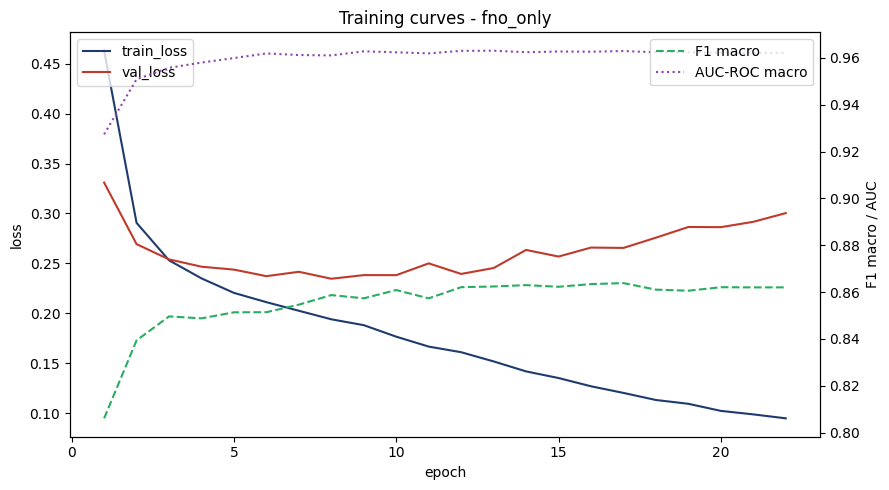

In [19]:
# Plot training and validation curves for the last seed executed.
x = range(1, len(history["train_loss"]) + 1)

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(x, history["train_loss"], label="train_loss", color="#1f3b6e")
ax1.plot(x, history["val_loss"], label="val_loss", color="#c0392b")
ax1.set_xlabel("epoch")
ax1.set_ylabel("loss")
ax1.legend(loc="upper left")

# Display validation F1-macro and AUC-ROC on a secondary axis.
ax2 = ax1.twinx()
ax2.plot(x, history["val_f1_macro"], label="F1 macro", color="#27ae60", ls="--")
ax2.plot(x, history["val_auc_macro"], label="AUC-ROC macro", color="#8e44ad",
         ls=":")
ax2.set_ylabel("F1 macro / AUC")
ax2.legend(loc="upper right")

plt.title(f"Training curves - {ARCH_NAME}")
plt.tight_layout()
plt.show()